# Proyecto final · Retrasos de vuelos en Estados Unidos

**Machine Learning · Universidad EIA**
**Autor:** Julián

Una fila es un **vuelo programado**. La pregunta es si llegará **15 minutos o más tarde** que el itinerario.
La predicción se emite **a la hora de salida programada**, así que solo puede usar lo que ya se sabe en ese
instante: itinerario, ruta, calendario, congestión programada del aeropuerto y cómo venía la aeronave en su
tramo anterior. Todo lo que se mide *durante* o *después* del vuelo es **fuga** y está prohibido.

Periodo: **junio 2025 – mayo 2026** (12 meses calendario, un ciclo estacional completo).

El recorrido es el de la sesión 6: **1 ¿ML?** · **2 Datos** · **3 Limpieza** · **4 Columnas** · **5 Modelos** · **6 Evaluación**.

> **Cómo se corre en la exposición:** `Kernel → Restart & Run All` con `MODO_RAPIDO = True` en `src/config.py`.
> Con `MODO_RAPIDO = False` salen los números finales del informe (tarda bastante más).
> Semilla fija (`SEMILLA = 42`): los números coinciden con los de las láminas.

In [1]:
# Todo el código vive en src/. El notebook solo cuenta la historia y muestra resultados.
import sys, json, time
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config as cfg
from src import datos, columnas, modelos, evaluacion

np.random.seed(cfg.SEMILLA)
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 60)

print("Raíz    :", RAIZ)
print("Periodo :", cfg.MES_INICIO, "→", cfg.MES_FIN)
print("Modo    :", "RÁPIDO (exposición)" if cfg.MODO_RAPIDO else "COMPLETO (informe)")
print("Semilla :", cfg.SEMILLA, "| XGBoost disponible:", modelos.HAY_XGB)

Raíz    : c:\Users\HP\Downloads\proyecto-vuelos-ml
Periodo : 2025-06 → 2026-05
Modo    : RÁPIDO (exposición)
Semilla : 42 | XGBoost disponible: True


---
## 1 · ¿Hace falta machine learning?

Un retraso cuesta combustible, tripulación, puertas y conexiones perdidas, y el US DOT publica rankings de
puntualidad: tiene costo económico y reputacional. Con el aviso **a la hora de salida** la aerolínea reasigna
puertas y el pasajero reorganiza su conexión, así que la predicción sirve para actuar.

| Pregunta | Respuesta |
|---|---|
| ¿Hay un patrón que aprender? | **Sí.** El retraso depende de la hora, del aeropuerto, de la aerolínea, de la congestión programada y de si la aeronave ya venía retrasada. Se verifica con datos en el paso 4. |
| ¿Hay etiqueta? | **Sí.** `ARR_DEL15` viene en los datos (1 = llegó con ≥ 15 min de retraso). No hay que inventarla. |
| ¿Hay suficientes datos? | **Sí**, millones de vuelos en 12 meses. Se confirma al cargar, en el paso 2. |
| ¿Una regla a mano ya basta? | **Se mide, no se supone.** Se formula abajo, se calibra en el paso 5 y compite en la misma tabla. |
| ¿Cuánto cuesta equivocarse? | Un **falso negativo** (no avisar un retraso) hace perder una conexión; un **falso positivo** genera una alerta inútil. El primero cuesta más, así que se vigilan el **recall** y el **F1**, no la exactitud. |

**La regla a mano:** *«si el vuelo sale a las HH:00 o después, llegará retrasado»*. La hora `HH` se busca
**solo con el entrenamiento** en el paso 5. La regla está escrita como un estimador de sklearn
(`modelos.ReglaManual`) para que pase por la misma validación cruzada que los modelos: la comparación es justa.

**Por qué la exactitud no sirve aquí.** Cerca del 80 % de los vuelos llega a tiempo: decir siempre «puntual»
ya acierta ese 80 % sin encontrar un solo retraso. La métrica principal es el **AUC**, acompañada de
**PR-AUC**, **recall** y **F1**.

---
## 2 · Los datos

| | |
|---|---|
| **Página** | https://www.kaggle.com/datasets/umerhafeezsiddiqui/2021-2026-us-flights |
| **Quién publica** | Recopilado en Kaggle por `umerhafeezsiddiqui` a partir del reporte *On-Time Performance* del **Bureau of Transportation Statistics** (BTS), del U.S. Department of Transportation. Los nombres de columna (`FL_DATE`, `OP_UNIQUE_CARRIER`, `CRS_DEP_TIME`, `ARR_DEL15`…) son los del formulario oficial del BTS. |
| **Licencia** | ✍️ *Copiar el campo «License» de la barra lateral de Kaggle.* El reporte original del BTS es obra del gobierno federal de EE. UU.: **dominio público**. |
| **Cómo se descarga** | Un CSV por mes (`Jun-2025.csv`, `Jul-2025.csv`, …) que se dejan en `datos/crudos/`. |
| **Qué es una fila** | **Un vuelo programado**: un tramo origen → destino, de una aerolínea, en una fecha. Incluye los que terminaron cancelados o desviados. |
| **Etiqueta** | `retraso15` = `ARR_DEL15` = 1 si el vuelo llegó con **≥ 15 min** de retraso (definición oficial del DOT). |

**Complejidad del origen (criterio «complejidad», 25 %).** No es un archivo ya limpio: son **12 CSV mensuales**
de varios GB que hay que unir, recortar al periodo y convertir a tipos pequeños para que quepan en memoria.
Además, la **tabla principal la armamos nosotros**: la rotación de cada aeronave (el retraso de su tramo anterior)
no viene en los datos, se deduce ordenando por `TAIL_NUM` y reconstruyendo los husos horarios a partir del
itinerario, sin ninguna tabla externa.

> En la exposición se abre la página de Kaggle **en vivo** antes de correr esta celda.

In [3]:
df = datos.cargar()          # lee datos/crudos/*.csv por bloques y guarda caché en parquet
print(f"\nTabla cruda: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print("Rango de fechas:", df.fecha.min().date(), "→", df.fecha.max().date())
display(df.head(4))

  leído Apr-2026.csv
  leído Aug-2025.csv
  leído Dec-2025.csv
  leído Feb-2026.csv
  leído Jan-2026.csv
  leído Jul-2025.csv
  leído Jun-2025.csv
  leído Mar-2026.csv
  leído May-2026.csv
  leído Nov-2025.csv
  leído Oct-2025.csv
  leído Sep-2025.csv
Caché guardada en datos\procesados\vuelos_2025-06_2026-05.parquet

Tabla cruda: 7,786,702 filas × 19 columnas
Rango de fechas: 2025-06-01 → 2026-05-31


,YEAR,MONTH,DAY_OF_MONTH,FL_DATE,OP_UNIQUE_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_DELAY,CRS_ARR_TIME,ARR_DELAY,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE,fecha
0,2026,4,1,04-01-26 00:00,9E,N131EV,4969,XNA,LGA,1150,68.0,1547,69.0,1.0,0,0,177.0,1147,2026-04-01
1,2026,4,1,04-01-26 00:00,9E,N131EV,5348,LGA,ORF,1633,70.0,1803,106.0,1.0,0,0,90.0,296,2026-04-01
2,2026,4,1,04-01-26 00:00,9E,N131EV,5348,ORF,LGA,1843,NaN,2012,NaN,NaN,1,0,89.0,296,2026-04-01
3,2026,4,1,04-01-26 00:00,9E,N131EV,5402,DSM,MSP,655,-9.0,814,-20.0,0.0,0,0,79.0,232,2026-04-01


Meses esperados: 12 · presentes: 12 · faltantes: ninguno


,periodo,vuelos,dias,aerolineas,aeropuertos
0,2025-06,674179,30,20,360
1,2025-07,696049,31,20,360
2,2025-08,666242,31,20,363
3,2025-09,621601,30,20,360
4,2025-10,668332,31,20,361
5,2025-11,630188,30,20,357
6,2025-12,644987,31,20,359
7,2026-01,602953,31,19,359
8,2026-02,568789,28,19,362
9,2026-03,675500,31,19,361


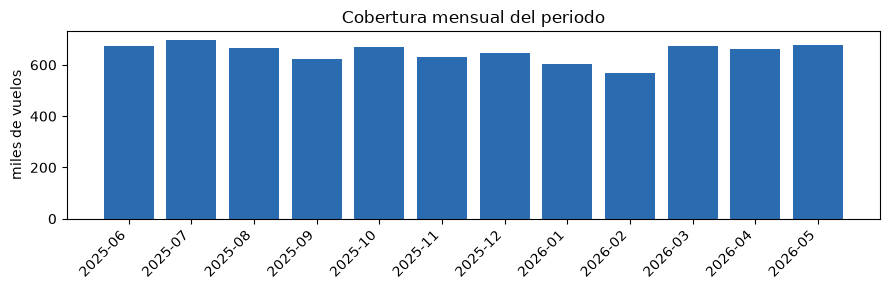

In [4]:
# ¿Están los 12 meses, y con un volumen parecido? Si falta un mes, la comparación temporal queda sesgada.
cobertura = datos.cobertura_mensual(df)
display(cobertura)

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(cobertura["periodo"], cobertura["vuelos"] / 1_000, color=evaluacion.AZUL)
ax.set(title="Cobertura mensual del periodo", ylabel="miles de vuelos")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

---
## 3 · Limpieza

Cada decisión se imprime **con su conteo**. La regla del paso: aquí solo se arregla lo que es un hecho objetivo
de los datos (formatos, duplicados, filas imposibles). **Nada que se aprenda de los datos —medias, medianas,
codificaciones— se hace aquí**: todo eso vive dentro del `Pipeline` del paso 5, que se reajusta en cada pliegue.

1. **Nulos.** Las cinco columnas de *causas* del retraso (`CARRIER_DELAY`, `WEATHER_DELAY`, `NAS_DELAY`,
   `SECURITY_DELAY`, `LATE_AIRCRAFT_DELAY`) pasan del 50 % de nulos porque **solo se llenan cuando ya hubo
   retraso**: además de vacías son fuga. Ni siquiera se leen del CSV.
2. **Cancelados y desviados.** Un vuelo que nunca llegó **no tiene retraso de llegada y no tiene etiqueta**.
   ⚠️ *El error que hay que evitar es taparlos con la mediana*: eso le inventa una etiqueta falsa a cada
   cancelado y, peor, le inventa una hora de llegada al tramo anterior de la aeronave, que es justamente la
   variable más predictiva del paso 4. Se marcan con `tiene_etiqueta` y **se filtran al final del paso 4**,
   porque sus horarios programados sí cuentan para la congestión y la rotación.
3. **Itinerarios imposibles.** Sin hora programada, duración o distancia no hay vuelo que predecir: se eliminan.
4. **Duplicados.** Clave: fecha + aerolínea + número de vuelo + origen + destino + hora programada.
5. **Formatos.** La fecha se arma con `YEAR`/`MONTH`/`DAY_OF_MONTH`, no con `FL_DATE` (su formato `06-01-25` es
   ambiguo entre día y mes). Las horas vienen como entero `hhmm` y a veces llegan a `2400`: se convierten a
   minutos con `% 1440`, de modo que `2400` cae en `0`.
6. **Atípicos.** Los retrasos de más de un día **son reales**: no se borra ninguna fila. Como etiqueta no
   estorban; como variable se recortan a `[-60, +360]` minutos con **constantes fijas**, no con percentiles
   calculados sobre los datos, así que el recorte no introduce fuga.

In [5]:
foto_antes = datos.foto(df, "ANTES")

display(datos.nulos_por_columna(df))
df, bitacora = datos.limpiar(df)

print(f"Cancelados   : {bitacora['cancelados']:>10,}")
print(f"Desviados    : {bitacora['desviados']:>10,}")
print(f"Sin etiqueta : {bitacora['sin_etiqueta']:>10,}")
print(f"Itinerarios inválidos eliminados: {bitacora['itinerarios_invalidos']:,}")
print(f"Duplicados eliminados           : {bitacora['duplicados']:,}")
print(f"\nCoherencia ARR_DEL15 vs (ARR_DELAY >= {cfg.UMBRAL_RETRASO}): {bitacora['coherencia_etiqueta']:.4%}")
print(f"Tasa de retraso entre vuelos con etiqueta     : {bitacora['tasa_retraso']:.2%}")
print(f"Línea base 'siempre a tiempo'                 : exactitud {1 - bitacora['tasa_retraso']:.2%}, "
      f"pero recall 0 % y F1 0")

,% nulos
ARR_DEL15,2.14
ARR_DELAY,2.14
DEP_DELAY,1.80
TAIL_NUM,0.30


Cancelados   :    145,007
Desviados    :     21,637
Sin etiqueta :    166,645
Itinerarios inválidos eliminados: 18
Duplicados eliminados           : 0

Coherencia ARR_DEL15 vs (ARR_DELAY >= 15): 100.0000%
Tasa de retraso entre vuelos con etiqueta     : 22.44%
Línea base 'siempre a tiempo'                 : exactitud 77.56%, pero recall 0 % y F1 0


In [6]:
display(datos.resumen_atipicos(df))

comparacion = pd.concat([foto_antes, datos.foto(df, "DESPUÉS")], axis=1)
comparacion["cambio"] = comparacion["DESPUÉS"] - comparacion["ANTES"]
display(comparacion)
comparacion.to_csv(cfg.RESULTADOS / "tabla_antes_despues.csv")
print(f"Se eliminó el {1 - len(df) / foto_antes['filas']:.3%} de las filas: solo itinerarios "
      f"imposibles y duplicados.")
print("Los cancelados y desviados SIGUEN aquí: se usan para congestión y rotación en el paso 4.")

,count,mean,std,min,1%,50%,99%,max
ARR_DELAY,7620055.0,8.549687,61.510223,-109.0,-37.0,-6.0,231.0,4336.0
CRS_ELAPSED_TIME,7620055.0,145.353248,71.444745,9.0,51.0,128.0,374.0,1202.0
DISTANCE,7620055.0,805.577426,592.634750,31.0,93.0,646.0,2611.0,5095.0


,ANTES,DESPUÉS,cambio
filas,7786702.00,7786684.000,-18.000
columnas,19.00,20.000,1.000
memoria (GB),0.86,0.919,0.059
duplicados,0.00,0.000,0.000
cancelados,145007.00,145002.000,-5.000
desviados,21637.00,21626.000,-11.000
% nulos CRS_ELAPSED_TIME,0.00,0.000,0.000
% nulos ARR_DELAY,2.14,2.140,0.000
% nulos ARR_DEL15,2.14,2.140,0.000
% nulos TAIL_NUM,0.30,0.300,0.000


Se eliminó el 0.000% de las filas: solo itinerarios imposibles y duplicados.
Los cancelados y desviados SIGUEN aquí: se usan para congestión y rotación en el paso 4.


---
## 4 · Columnas

> **Regla de oro anti-fuga:** una columna entra **solo si su valor se conoce a la hora de salida programada**.
> Entra todo lo que sale del itinerario publicado; no entra nada que se mida durante o después del vuelo.

| Columna nueva | Qué es | Por qué ayuda | ¿Se conoce antes de salir? |
|---|---|---|---|
| `hora_sal_dec`, `hora_lleg` | hora programada de salida / llegada | los retrasos se acumulan durante el día | sí, está en el itinerario |
| `dia_semana`, `dias_a_festivo` | calendario | viernes y vísperas de festivo saturan los aeropuertos | sí, es el calendario |
| `vuelos_origen_hora`, `vuelos_destino_hora` | vuelos **programados** en ese aeropuerto y esa hora | congestión conocida de antemano | sí: se cuenta sobre la programación publicada, incluidos los que luego se cancelan |
| `tramo_del_dia` | número de tramo de esa aeronave ese día | más tramos, más retraso acumulado | sí, sale de la programación |
| `holgura_prog` | minutos programados entre el aterrizaje anterior y esta salida | poca holgura, poca capacidad de absorber un retraso | sí |
| `ret_prev_llegada` | retraso del **tramo anterior de la misma aeronave**, y solo si ya había aterrizado antes de esta salida | **propagación**: un avión que llega tarde sale tarde | sí, con esa condición |
| `prev_disponible` | bandera: ¿se conocía ese tramo anterior? | el faltante **no es aleatorio**, y eso informa | sí |

Para armar la rotación se ordena por `TAIL_NUM` y hora. El desfase de husos horarios se deduce del propio
itinerario (`llegada programada − salida − duración`), sin tabla externa.

In [7]:
df = columnas.crear_columnas(df)
tabla = columnas.tabla_modelado(df)     # aquí sí se filtran los vuelos sin etiqueta
del df

print(f"Tabla de modelado: {tabla.shape[0]:,} vuelos × {tabla.shape[1]} columnas")
print(f"Tasa de retraso >= {cfg.UMBRAL_RETRASO} min: {tabla[cfg.OBJETIVO].mean():.2%}  (clase 1 = retrasado)")
display(tabla.head(5))

Tabla de modelado: 7,620,055 vuelos × 19 columnas
Tasa de retraso >= 15 min: 22.44%  (clase 1 = retrasado)


,fecha,retraso15,DEP_DELAY,hora_sal,DISTANCE,CRS_ELAPSED_TIME,hora_sal_dec,hora_lleg,dias_a_festivo,vuelos_origen_hora,vuelos_destino_hora,tramo_del_dia,holgura_prog,ret_prev_llegada,prev_disponible,OP_UNIQUE_CARRIER,ORIGIN,DEST,dia_semana
0,2026-04-01,1,68.0,11,1147,177,11.833333,15,15,5,31,3,41.0,-3.0,1,9E,XNA,LGA,2
1,2026-04-01,1,70.0,16,296,90,16.549999,18,15,31,6,4,46.0,NaN,0,9E,LGA,ORF,2
2,2026-04-01,0,-9.0,6,232,79,6.916667,8,15,6,23,1,610.0,149.0,1,9E,DSM,MSP,2
3,2026-04-01,0,7.0,9,596,125,9.066667,11,15,17,6,2,50.0,-20.0,1,9E,MSP,XNA,2
4,2026-04-01,0,-11.0,6,143,72,6.833333,8,15,2,92,1,628.0,-10.0,1,9E,AGS,ATL,2


In [8]:
display(columnas.tabla_decisiones())
columnas.tabla_decisiones().to_csv(cfg.RESULTADOS / "tabla_columnas.csv", index=False)

,columna original,decisión,en qué se convierte
0,YEAR / MONTH / DAY_OF_MONTH / FL_DATE,se transforma,fecha · dia_semana · dias_a_festivo
1,OP_UNIQUE_CARRIER,ENTRA (categórica),codificación por objetivo dentro del Pipeline
2,ORIGIN / DEST,ENTRAN (categóricas),codificación por objetivo dentro del Pipeline
3,CRS_DEP_TIME,se transforma,hora_sal · hora_sal_dec
4,CRS_ARR_TIME,se transforma,hora_lleg · desfase horario
5,CRS_ELAPSED_TIME / DISTANCE,ENTRAN (numéricas),imputación y escalado dentro del Pipeline
6,TAIL_NUM,"se usa, no entra",ret_prev_llegada · holgura_prog · tramo_del_dia
7,OP_CARRIER_FL_NUM,DESCARTADA · identificador,solo sirve para detectar duplicados
8,ARR_DEL15,ES LA ETIQUETA,retraso15
9,ARR_DELAY,DESCARTADA · fuga (se mide durante o después d...,el del tramo ANTERIOR sí se usa: ret_prev_llegada


### 4.1 ¿Se confirman las hipótesis? (mirar antes de modelar)

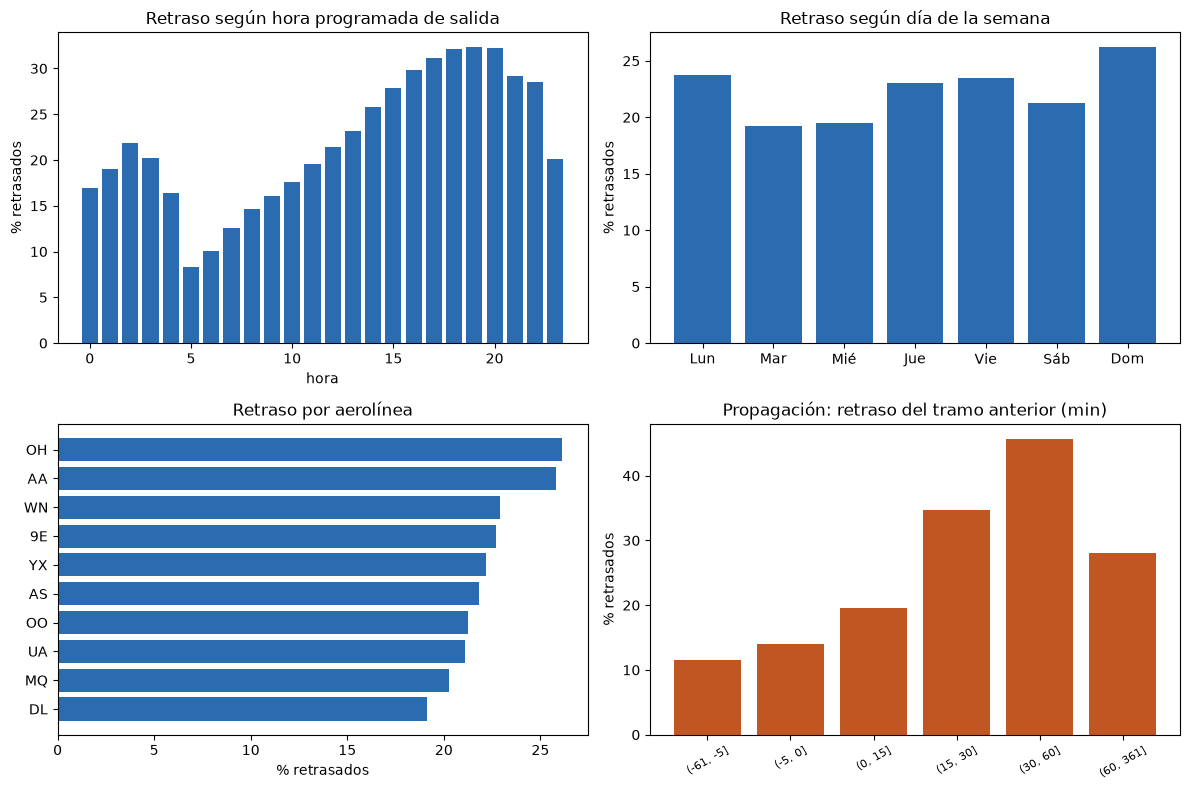

In [9]:
evaluacion.grafica_hipotesis(tabla); plt.show()

### 4.2 Faltantes: ¿con qué se imputa `ret_prev_llegada`?

Falta cuando el tramo anterior no existe, no se conoce, o **aún no había aterrizado** a la hora de salida
programada. Ese faltante **no es aleatorio**: por eso se conserva la bandera `prev_disponible` junto al valor.

Para elegir el método se **oculta a propósito el 25 % de los valores conocidos**, se estima con cada opción y
se mide el error en minutos (MAE) — el mismo experimento que con la edad en el Titanic.

In [10]:
imputacion = columnas.comparar_imputacion(tabla)
display(imputacion)
imputacion.to_csv(cfg.RESULTADOS / "comparacion_imputacion.csv")
print(f"Desviación típica de la variable: {imputacion.attrs['desviacion']:.1f} min")
ganancia = imputacion.loc["Mediana global", "MAE (min)"] - imputacion.iloc[0, 0]
print(f"Mejor opción: {imputacion.index[0]} (MAE {imputacion.iloc[0, 0]:.2f} min). "
      f"Gana {ganancia:.2f} min frente a la mediana global, sobre una desviación de "
      f"{imputacion.attrs['desviacion']:.1f} min.")

,MAE (min)
Mediana por hora de salida,19.102
Mediana global,19.223
Regresión (HistGB),20.413
Media global,20.718


Desviación típica de la variable: 35.8 min
Mejor opción: Mediana por hora de salida (MAE 19.10 min). Gana 0.12 min frente a la mediana global, sobre una desviación de 35.8 min.


**Decisión.** Dentro del `Pipeline` se imputa con la **mediana** (robusta a los retrasos extremos) acompañada
de la bandera `prev_disponible`, que es la que carga la información de «no se sabía». Si la ganancia de la
regresión es pequeña frente a la desviación típica de la variable, no compensa meter un modelo dentro del
preprocesamiento.
✍️ *Escribir aquí la lectura con los números de la corrida.*

### 4.3 Las tres barreras contra la fuga

1. **Al armar la tabla** — a la tabla de modelado solo pasa una **lista explícita** de columnas conocidas antes
   del vuelo (`config.NUMERICAS` y `config.CATEGORICAS`). Lo que no está en esa lista no puede llegar a `X`.
2. **Al construir** — `ret_prev_llegada` solo se llena si el tramo anterior **ya había aterrizado** antes de
   esta salida programada; la congestión se cuenta sobre vuelos **programados**, no sobre los que volaron.
3. **En el `Pipeline`** — imputación, escalado y codificación por objetivo se ajustan **dentro de cada pliegue**,
   con los datos de entrenamiento de ese pliegue. Nunca tocan la validación ni la prueba.

Y un `assert` que hace fallar el notebook si una columna prohibida se cuela.

In [11]:
columnas.verificar_sin_fuga()

# Demostración: se deja entrar a propósito DEP_DELAY, que solo se conoce cuando el avión YA salió.
display(evaluacion.demostrar_fuga(tabla, cfg.NUMERICAS))
print("Ese AUC no se puede obtener en la vida real antes del despegue: es la firma de una fuga.")
tabla = tabla.drop(columns=["DEP_DELAY"])      # cumplida su función, la columna sale

Verificación anti-fuga superada: 11 numéricas + 4 categóricas, ninguna prohibida.


,AUC
Sin fuga (solo columnas legítimas),0.8030
CON fuga (+ DEP_DELAY),0.9265


Ese AUC no se puede obtener en la vida real antes del despegue: es la firma de una fuga.


---
## 5 · Modelos

### Validación temporal estricta

Barajar las filas al azar sería hacer trampa: un modelo entrenado con vuelos del 15 de marzo que predice vuelos
del 14 está viendo el futuro. Todo se parte **por tiempo**:

- **Prueba final:** el último 15 % del calendario (≈ 2 meses). No se toca hasta el paso 6, y una sola vez.
- **Validación cruzada:** `TimeSeriesSplit` sobre el entrenamiento. Cada pliegue entrena con el pasado y valida
  con el bloque de tiempo siguiente, nunca al revés.
- **La misma vara para todos:** los mismos datos, los mismos pliegues y el preprocesamiento **dentro del
  `Pipeline`**, reajustado en cada pliegue.

In [12]:
fechas = np.sort(tabla["fecha"].unique())
corte = fechas[int(len(fechas) * (1 - cfg.FRACCION_PRUEBA))]
entrenamiento = tabla[tabla["fecha"] < corte]
prueba = tabla[tabla["fecha"] >= corte]

def tomar(d, n):
    """n filas al azar (con semilla), ordenadas por fecha. n=None -> todas. TimeSeriesSplit exige el orden."""
    return d.sort_values("fecha") if (n is None or n >= len(d)) else d.sample(n, random_state=cfg.SEMILLA).sort_values("fecha")

m_final = tomar(entrenamiento, cfg.N_FINAL)
m_cv    = tomar(m_final, cfg.N_CV)
m_test  = tomar(prueba, cfg.N_TEST)

X_cv,  y_cv  = columnas.armar_X(m_cv),    m_cv[cfg.OBJETIVO].to_numpy()
X_fin, y_fin = columnas.armar_X(m_final), m_final[cfg.OBJETIVO].to_numpy()
X_tst, y_tst = columnas.armar_X(m_test),  m_test[cfg.OBJETIVO].to_numpy()

print("Corte temporal:", pd.Timestamp(corte).date())
print(f"Entrenamiento : {len(entrenamiento):,} vuelos ({entrenamiento.fecha.min().date()} → {entrenamiento.fecha.max().date()})")
print(f"Prueba final  : {len(prueba):,} vuelos ({prueba.fecha.min().date()} → {prueba.fecha.max().date()})")
print(f"\nMuestras → CV {len(X_cv):,} · entrenamiento final {len(X_fin):,} · prueba {len(X_tst):,}")
print(f"Tasa de retraso → CV {y_cv.mean():.2%} · final {y_fin.mean():.2%} · prueba {y_tst.mean():.2%}")

Corte temporal: 2026-04-07
Entrenamiento : 6,428,154 vuelos (2025-06-01 → 2026-04-06)
Prueba final  : 1,191,901 vuelos (2026-04-07 → 2026-05-31)

Muestras → CV 60,000 · entrenamiento final 200,000 · prueba 200,000
Tasa de retraso → CV 22.91% · final 22.90% · prueba 20.27%


In [13]:
# La hora de corte de la regla se busca SOLO en el entrenamiento.
HORA_REGLA, f1_regla = modelos.calibrar_regla(X_fin["hora_sal_dec"], y_fin)
print(f"Regla a mano calibrada: «si el vuelo sale a las {HORA_REGLA}:00 o después, llegará retrasado»")
print(f"F1 en el entrenamiento: {f1_regla:.3f}  <- este es el número a vencer")

Regla a mano calibrada: «si el vuelo sale a las 12:00 o después, llegará retrasado»
F1 en el entrenamiento: 0.413  <- este es el número a vencer


### Comparación multi-familia

Se compara **una familia distinta por entrada**, no siete variantes del mismo árbol:

| Modelo | Familia | Sesión |
|---|---|---|
| Línea base («siempre a tiempo») | trivial | — |
| Regla a mano (hora de corte) | regla experta | — |
| Regresión logística | lineal | S3 |
| Árbol de decisión | árbol único | S4 |
| Random forest | ensamble por *bagging* | S5 |
| HistGradientBoosting | ensamble por *boosting* | S5 |
| XGBoost | *boosting* regularizado | S7 |
| Red neuronal (MLP) | red neuronal | S8 |

KNN y SVM con kernel se descartan **a propósito**: con cientos de miles de filas su costo es cuadrático y no
aportan una familia que no esté ya representada. Es una decisión que se defiende, no se esconde.

**El umbral.** El 0,50 de sklearn no es una decisión de negocio: con un 20 % de retrasos deja al modelo casi mudo.
Se elige el umbral que maximiza el F1 **en el último pliegue de validación**, nunca en la prueba.

In [14]:
print("Entrenando el catálogo con los mismos pliegues...\n")
tabla_cv = modelos.comparar_modelos(X_cv, y_cv, hora_regla=HORA_REGLA)
display(tabla_cv.round(4))
tabla_cv.to_csv(cfg.RESULTADOS / "tabla_modelos_cv.csv")

Entrenando el catálogo con los mismos pliegues...

  Línea base (siempre a tiempo)    AUC 0.5000  F1 0.000  (0 s)
  Regla a mano                     AUC 0.5811  F1 0.393  (0 s)
  Regresión logística              AUC 0.7379  F1 0.521  (1 s)
  Árbol de decisión                AUC 0.7820  F1 0.595  (1 s)
  Random forest                    AUC 0.7893  F1 0.591  (2 s)
  HistGradientBoosting             AUC 0.7950  F1 0.596  (2 s)
  Red neuronal (MLP)               AUC 0.7811  F1 0.589  (13 s)
  XGBoost                          AUC 0.7913  F1 0.592  (2 s)


,AUC,AUC_std,PR-AUC,F1,Recall,Precisión,Exactitud,umbral,seg
modelo,,,,,,,,,
HistGradientBoosting,0.7950,0.0032,0.6552,0.5964,0.5687,0.6269,0.8244,0.2951,1.5
XGBoost,0.7913,0.0044,0.6495,0.5915,0.5453,0.6463,0.8282,0.3295,2.1
Random forest,0.7893,0.0040,0.6408,0.5910,0.5520,0.6358,0.8257,0.3030,2.1
Árbol de decisión,0.7820,0.0015,0.6322,0.5949,0.5766,0.6145,0.8209,0.2707,0.7
Red neuronal (MLP),0.7811,0.0077,0.6269,0.5892,0.5678,0.6124,0.8194,0.2952,12.8
Regresión logística,0.7379,0.0033,0.5541,0.5205,0.5114,0.5300,0.7851,0.2554,0.7
Regla a mano,0.5811,0.0060,0.2463,0.3931,0.6937,0.2743,0.5114,0.5000,0.1
Línea base (siempre a tiempo),0.5000,0.0000,0.2133,0.0000,0.0000,0.0000,0.7719,0.5000,0.1


---
## 6 · Evaluación

| Métrica | Qué responde | Por qué importa aquí |
|---|---|---|
| **ROC-AUC** | ¿ordena bien los vuelos de más a menos riesgo? | métrica principal; no depende del umbral |
| **PR-AUC** | ¿acierta en la clase rara? | la adecuada cuando hay desbalance |
| **Recall** | de los vuelos que se retrasaron, ¿a cuántos avisó? | el falso negativo es el error caro |
| **Precisión** | de los que avisó, ¿cuántos se retrasaron? | las alertas falsas tienen costo operativo |
| **F1** | equilibrio entre las dos anteriores | con el umbral elegido en validación |
| **Exactitud** | se reporta solo para mostrar que **engaña** | comparar con la línea base |

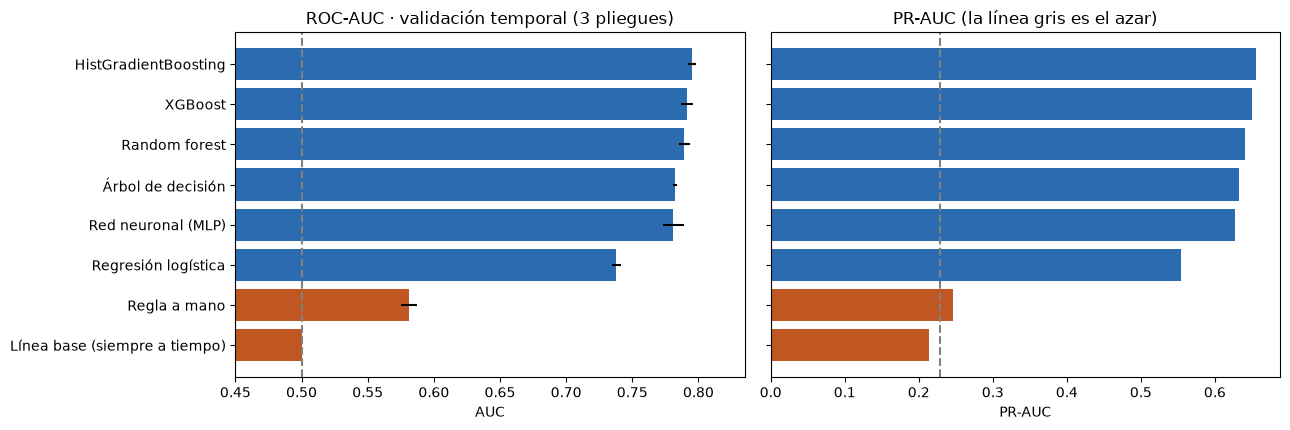

Naranja = referencias (línea base y regla a mano). Las barras negras son la variación entre pliegues.


In [15]:
evaluacion.grafica_comparacion(tabla_cv, y_cv.mean(), modelos.REFERENCIAS); plt.show()
print("Naranja = referencias (línea base y regla a mano). Las barras negras son la variación entre pliegues.")

### Elección argumentada

No siempre gana el número más alto. La regla de decisión se fija **antes** de mirar la prueba:

> Entre los modelos de ML cuyo AUC esté **dentro de una desviación típica del mejor**, se elige **el más simple**.
> Un empate estadístico se rompe por interpretabilidad y costo, no por el tercer decimal.

In [16]:
ELEGIDO, UMBRAL, explicacion = modelos.elegir_modelo(tabla_cv, HORA_REGLA)
print(explicacion)

Mejor AUC          : HistGradientBoosting (0.7950)
Margen (1 desv.)   : 0.0032
Empatados dentro del margen: ['HistGradientBoosting']

-> Modelo elegido  : HistGradientBoosting  (el más simple del empate)
Umbral de decisión : 0.295  (máximo F1 en validación, nunca en la prueba)

Ventaja sobre la regla a mano en validación: +0.214 de AUC · +0.203 de F1


### Prueba final: datos del futuro, una sola vez

El modelo elegido se entrena con **toda** la muestra de entrenamiento y se evalúa en el último 15 % del
calendario, junto a la línea base y la regla a mano. Estas filas no influyeron en ninguna decisión anterior.

In [17]:
t0 = time.time()
modelo = modelos.construir(ELEGIDO, HORA_REGLA).fit(X_fin, y_fin)
print(f"{ELEGIDO} entrenado en {time.time() - t0:.0f} s con {len(X_fin):,} vuelos")

p_modelo = modelo.predict_proba(X_tst)[:, 1]
p_regla = modelos.ReglaManual(hora=HORA_REGLA).fit(X_fin, y_fin).predict_proba(X_tst)[:, 1]

tabla_test = evaluacion.evaluar_prueba(y_tst, p_modelo, UMBRAL, ELEGIDO, p_regla, y_fin.mean())
display(tabla_test)
tabla_test.to_csv(cfg.RESULTADOS / "tabla_prueba_final.csv")
print(f"La validación prometía AUC {tabla_cv.loc[ELEGIDO, 'AUC']:.3f}; la prueba dio "
      f"{tabla_test.loc[ELEGIDO, 'AUC']:.3f}.")

HistGradientBoosting entrenado en 3 s con 200,000 vuelos


,AUC,PR-AUC,F1,Recall,Precisión,Exactitud
modelo,,,,,,
HistGradientBoosting,0.8124,0.6695,0.5898,0.5733,0.6073,0.8384
Regla a mano,0.6004,0.2441,0.3833,0.7407,0.2586,0.5170
Línea base (siempre a tiempo),0.5000,0.2027,0.0000,0.0000,0.0000,0.7973


La validación prometía AUC 0.795; la prueba dio 0.812.


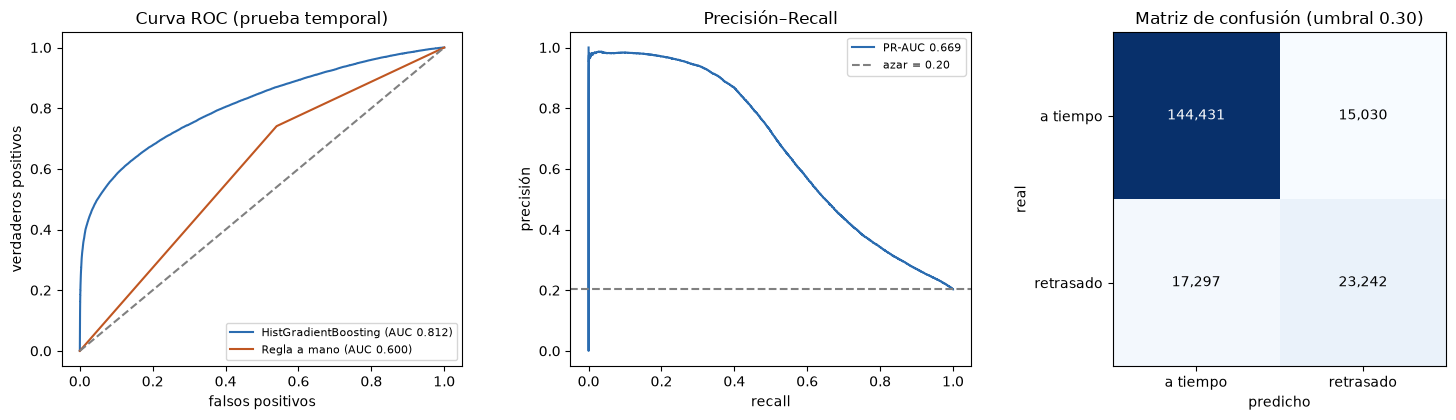

De 40,539 vuelos que se retrasaron, el modelo avisó 23,242 (57.3%).
De 38,272 alertas emitidas, 23,242 eran retrasos reales (60.7%).


In [18]:
fig, cm = evaluacion.grafica_prueba(y_tst, p_modelo, p_regla, UMBRAL, ELEGIDO, tabla_test)
plt.show()

vn, fp, fn, vp = cm.ravel()
print(f"De {vp + fn:,} vuelos que se retrasaron, el modelo avisó {vp:,} ({vp / (vp + fn):.1%}).")
print(f"De {vp + fp:,} alertas emitidas, {vp:,} eran retrasos reales ({vp / (vp + fp):.1%}).")

### ¿Qué columnas pesan más?

Se baraja una columna a la vez en la prueba y se mide cuánto cae el AUC: cuanto más cae, más depende el modelo
de ella. Esta gráfica es la **lectura de negocio** del proyecto.

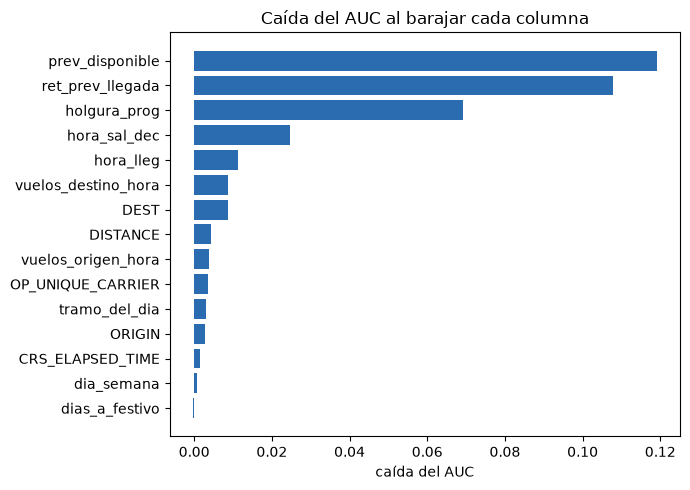

,caída del AUC
prev_disponible,0.119098
ret_prev_llegada,0.107720
holgura_prog,0.069222
hora_sal_dec,0.024780
hora_lleg,0.011291
vuelos_destino_hora,0.008714


In [19]:
fig, importancias = evaluacion.grafica_importancia(modelo, X_tst, y_tst)
plt.show()
importancias.to_csv(cfg.RESULTADOS / "importancia_columnas.csv", header=["caida_AUC"])
display(importancias.head(6).to_frame("caída del AUC"))

In [20]:
# Se guarda todo lo que hace falta para reproducir la corrida y para la exposición.
joblib.dump({"modelo": modelo, "nombre": ELEGIDO, "umbral": UMBRAL, "hora_regla": HORA_REGLA,
             "NUMERICAS": cfg.NUMERICAS, "CATEGORICAS": cfg.CATEGORICAS, "semilla": cfg.SEMILLA},
            cfg.MODELOS / "modelo_elegido.joblib")

resumen = {
    "problema": f"Retraso de llegada >= {cfg.UMBRAL_RETRASO} min, predicho a la hora de salida programada",
    "periodo": f"{cfg.MES_INICIO} a {cfg.MES_FIN}",
    "filas_tabla_modelado": int(len(tabla)),
    "tasa_retraso": round(float(tabla[cfg.OBJETIVO].mean()), 4),
    "modo_rapido": cfg.MODO_RAPIDO, "semilla": cfg.SEMILLA, "pliegues": cfg.K_PLIEGUES,
    "corte_temporal_prueba": str(pd.Timestamp(corte).date()),
    "modelo_elegido": ELEGIDO, "umbral": round(UMBRAL, 4), "regla_a_mano_hora": HORA_REGLA,
    "AUC_cv_elegido": round(float(tabla_cv.loc[ELEGIDO, "AUC"]), 4),
    "AUC_prueba_elegido": round(float(tabla_test.loc[ELEGIDO, "AUC"]), 4),
    "AUC_prueba_regla": round(float(tabla_test.loc["Regla a mano", "AUC"]), 4),
    "F1_prueba_elegido": round(float(tabla_test.loc[ELEGIDO, "F1"]), 4),
    "F1_prueba_regla": round(float(tabla_test.loc["Regla a mano", "F1"]), 4),
    "top3_columnas": importancias.head(3).round(4).to_dict(),
}
(cfg.RESULTADOS / "resumen_final.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False),
                                                   encoding="utf-8")
print(json.dumps(resumen, indent=2, ensure_ascii=False))

{
  "problema": "Retraso de llegada >= 15 min, predicho a la hora de salida programada",
  "periodo": "2025-06 a 2026-05",
  "filas_tabla_modelado": 7620055,
  "tasa_retraso": 0.2244,
  "modo_rapido": true,
  "semilla": 42,
  "pliegues": 3,
  "corte_temporal_prueba": "2026-04-07",
  "modelo_elegido": "HistGradientBoosting",
  "umbral": 0.2951,
  "regla_a_mano_hora": 12,
  "AUC_cv_elegido": 0.795,
  "AUC_prueba_elegido": 0.8124,
  "AUC_prueba_regla": 0.6004,
  "F1_prueba_elegido": 0.5898,
  "F1_prueba_regla": 0.3833,
  "top3_columnas": {
    "prev_disponible": 0.1191,
    "ret_prev_llegada": 0.1077,
    "holgura_prog": 0.0692
  }
}


---
## Conclusiones y límites

*(Escribirlas con los números de la corrida, antes de la exposición.)*

1. **¿Valió la pena ML?** Comparar AUC, PR-AUC y F1 del modelo elegido contra la **regla a mano** y la **línea
   base** en la tabla de la prueba final. Si la ventaja fuera pequeña, la respuesta honesta sería quedarse con
   la regla.
2. **¿Qué modelo se eligió y por qué?** Nombrar los que quedaron dentro de una desviación típica del mejor y
   explicar por qué ganó el más simple.
3. **¿Qué columnas pesan más?** ¿Manda la **propagación** (`ret_prev_llegada`), la **congestión** o el
   **calendario**?
4. **¿Dónde falla?** Mirar la matriz de confusión: ¿avisa poco (recall bajo) o avisa de más (precisión baja)?
   ¿Qué preferiría una aerolínea?
5. **Límites honestos.** No hay clima, ni control de tráfico aéreo en tiempo real, ni estado de la tripulación.
   Con `DEP_DELAY` el AUC sería mucho mayor, pero sería **fuga**: ese dato no existe antes de que el avión
   despegue. Por eso el techo de un modelo pre-vuelo está lejos de un AUC perfecto, y eso es correcto.